Import the libraries and load  dataset

In [63]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [64]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
sample_submission = pd.read_csv("sample_submission.csv")

In [65]:
train.head()

,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


In [66]:
train.tail()

,date,store,item,sales
912995,2017-12-27,10,50,63
912996,2017-12-28,10,50,59
912997,2017-12-29,10,50,74
912998,2017-12-30,10,50,62
912999,2017-12-31,10,50,82


In [67]:
print("Train:", train.shape)
print("Test:", test.shape)
print("Sample submission:", sample_submission.shape)

print("Test columns:", test.columns.tolist())


Train: (913000, 4)
Test: (45000, 4)
Sample submission: (45000, 2)
Test columns: ['id', 'date', 'store', 'item']


Data Inspection:

In [68]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 913000 entries, 0 to 912999
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   date    913000 non-null  object
 1   store   913000 non-null  int64 
 2   item    913000 non-null  int64 
 3   sales   913000 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 27.9+ MB


In [69]:
train.isnull().sum()

date     0
store    0
item     0
sales    0
dtype: int64

In [70]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      45000 non-null  int64 
 1   date    45000 non-null  object
 2   store   45000 non-null  int64 
 3   item    45000 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 1.4+ MB


In [71]:
train.duplicated().sum()

np.int64(0)

In [72]:
train.describe()

,store,item,sales
count,913000.000000,913000.000000,913000.000000
mean,5.500000,25.500000,52.250287
std,2.872283,14.430878,28.801144
min,1.000000,1.000000,0.000000
25%,3.000000,13.000000,30.000000
50%,5.500000,25.500000,47.000000
75%,8.000000,38.000000,70.000000
max,10.000000,50.000000,231.000000


Data Preprocessing

In [73]:
#CONVERT THE DATE FROM OBECT TO DATETIME
train["date"]=pd.to_datetime(train["date"],errors="raise")
test["date"]=pd.to_datetime(test["date"],errors="raise")

In [74]:
# Check the data types
print("Train date type:", train["date"].dtype)
print("Test date type:", test["date"].dtype)

Train date type: datetime64[ns]
Test date type: datetime64[ns]


In [75]:
#Sort by store, item, and date
train = train.sort_values(
    by=["store", "item", "date"]
).reset_index(drop=True)

test = test.sort_values(
    by=["store", "item", "date"]
).reset_index(drop=True)

display(train.head())
display(test.head())

,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


,id,date,store,item
0,0,2018-01-01,1,1
1,1,2018-01-02,1,1
2,2,2018-01-03,1,1
3,3,2018-01-04,1,1
4,4,2018-01-05,1,1


In [76]:
print("TRAIN MISSING VALUES")
print(train.isna().sum())

print("\nTEST MISSING VALUES")
print(test.isna().sum())

print(
    "\nDuplicate training combinations:",
    train.duplicated(["store", "item", "date"]).sum()
)

print(
    "Duplicate test combinations:",
    test.duplicated(["store", "item", "date"]).sum()
)

print("\nNegative sales:", (train["sales"] < 0).sum())

TRAIN MISSING VALUES
date     0
store    0
item     0
sales    0
dtype: int64

TEST MISSING VALUES
id       0
date     0
store    0
item     0
dtype: int64

Duplicate training combinations: 0
Duplicate test combinations: 0

Negative sales: 0


In [77]:
# Difference between consecutive dates for the same store and item
date_gaps = train.groupby(
    ["store", "item"]
)["date"].diff()


#["date"] selects the date column.
#.diff() subtracts the previous row’s date from the current row’s date, within each group.



# Ignore the first record of each group, which has no previous date
unexpected_gaps = (
    date_gaps.notna()   #.notna() checks whether a value is not missing.
    & (date_gaps != pd.Timedelta(days=1))
)

print("Unexpected date gaps:", unexpected_gaps.sum())

Unexpected date gaps: 0


In [78]:
print("\nTraining start:", train["date"].min())
print("Training end:", train["date"].max())

print("\nTest start:", test["date"].min())
print("Test end:", test["date"].max())


Training start: 2013-01-01 00:00:00
Training end: 2017-12-31 00:00:00

Test start: 2018-01-01 00:00:00
Test end: 2018-03-31 00:00:00


In [79]:
print("Number of stores:", train["store"].nunique())
print("Number of items:", train["item"].nunique())

Number of stores: 10
Number of items: 50


# EDA # Exploratory Data Analysis

In [80]:
print("Total units sold:", train["sales"].sum())

print(
    "Average units sold per store-item-day:",
    round(train["sales"].mean(), 2)
)

print("Number of stores:", train["store"].nunique())
print("Number of items:", train["item"].nunique())

Total units sold: 47704512
Average units sold per store-item-day: 52.25
Number of stores: 10
Number of items: 50


store
1     4315603
2     6120128
3     5435144
4     5012639
5     3631016
6     3627670
7     3320009
8     5856169
9     5025976
10    5360158
Name: sales, dtype: int64


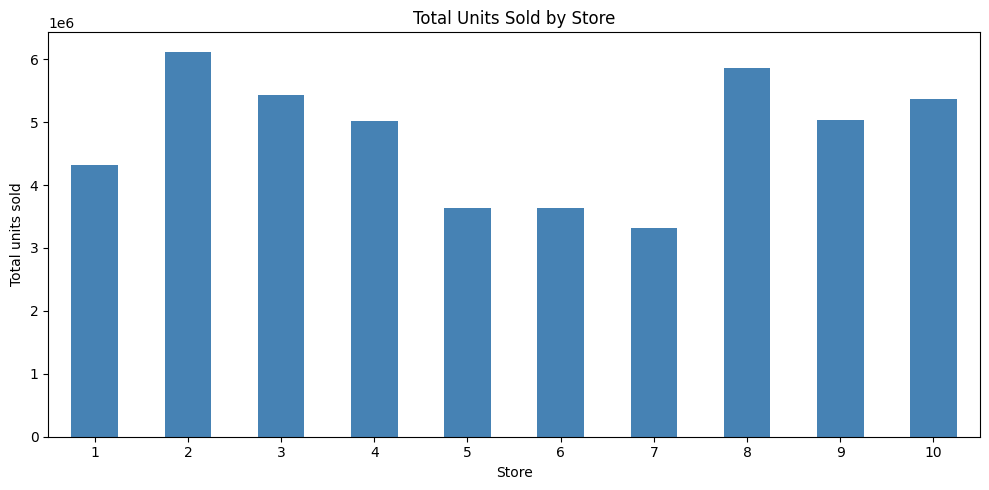

In [81]:
# Add up sales for each store
store_sales = train.groupby("store")["sales"].sum()

print(store_sales)

# Draw a bar chart
plt.figure(figsize=(10, 5))

store_sales.plot(kind="bar", color="steelblue")

plt.title("Total Units Sold by Store")
plt.xlabel("Store")
plt.ylabel("Total units sold")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

Store 2 recorded the highest total unit sales, while Store 7 recorded the lowest during 2013–2017.

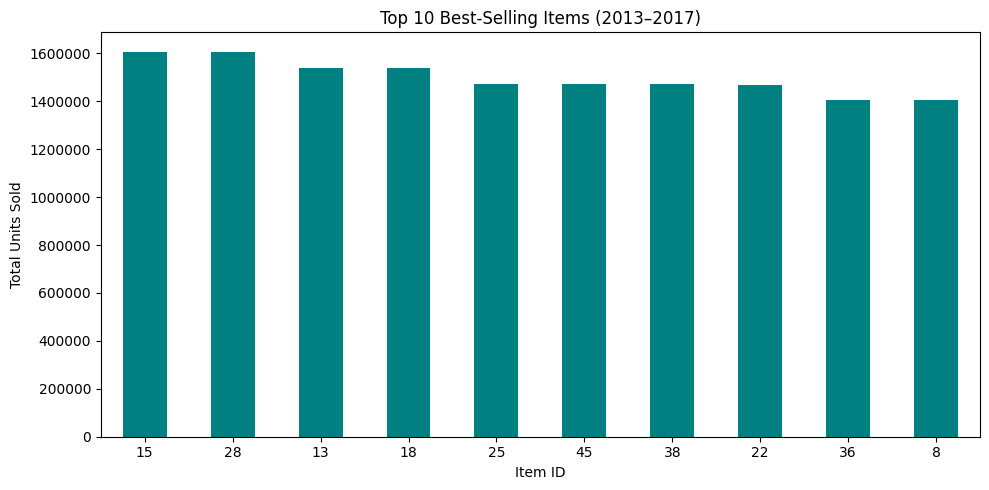

In [82]:
import matplotlib.pyplot as plt

# Calculate total units sold for each item
item_sales = train.groupby("item")["sales"].sum()

# Select the 10 items with the highest sales
top_10_items = item_sales.nlargest(10)

# Draw the graph
top_10_items.plot(
    kind="bar",
    figsize=(10, 5),
    color="teal"
)

plt.title("Top 10 Best-Selling Items (2013–2017)")
plt.xlabel("Item ID")
plt.ylabel("Total Units Sold")

plt.xticks(rotation=0)
plt.ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.show()

Conclusion: Item 15 had the highest total sales, followed closely by Item 28, with approximately 1.6 million units each across all stores during 2013–2017. Items 13 and 18 were the next highest-selling products.
Item 8 had the lowest sales within the top 10 shown, not among all 50 items. This chart identifies the historically best-selling products, which can help prioritize attention when planning inventory.

Visualize monthly sales

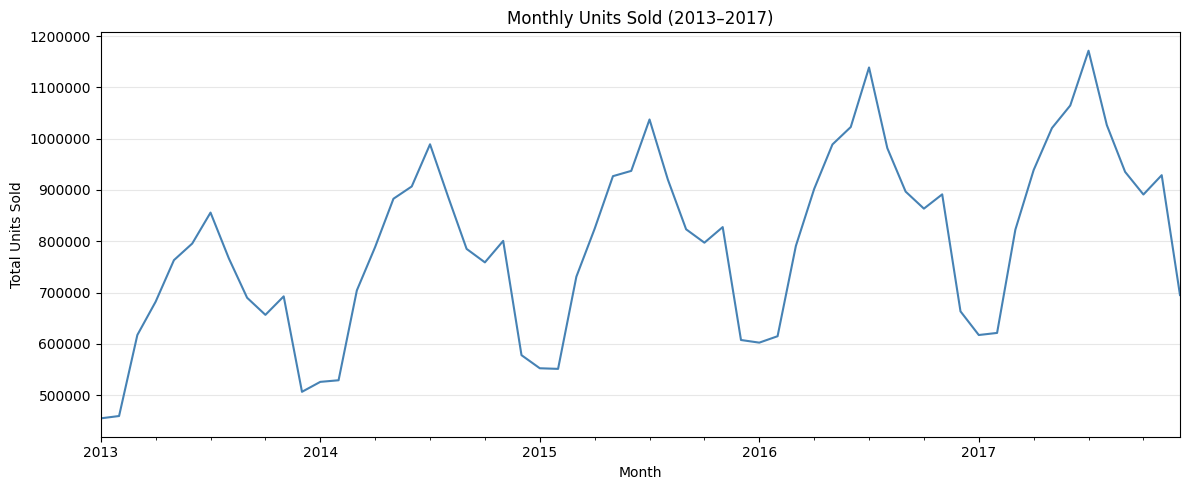

In [83]:
# Calculate total units sold in each month
monthly_sales = train.groupby(
    train["date"].dt.to_period("M")
)["sales"].sum()

# Draw the monthly sales graph
monthly_sales.plot(
    kind="line",
    figsize=(12, 5),
    color="steelblue"
)

plt.title("Monthly Units Sold (2013–2017)")
plt.xlabel("Month")
plt.ylabel("Total Units Sold")

plt.ticklabel_format(style="plain", axis="y")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Conclusion: Monthly sales show an overall upward trend from 2013 to 2017, along with a repeating yearly pattern.
- Sales generally rise toward the middle of each year and fall toward the end.
- This repeated rise and fall indicates yearly seasonality.
- The highest monthly sales occur in 2017, reaching approximately 1.17 million units.

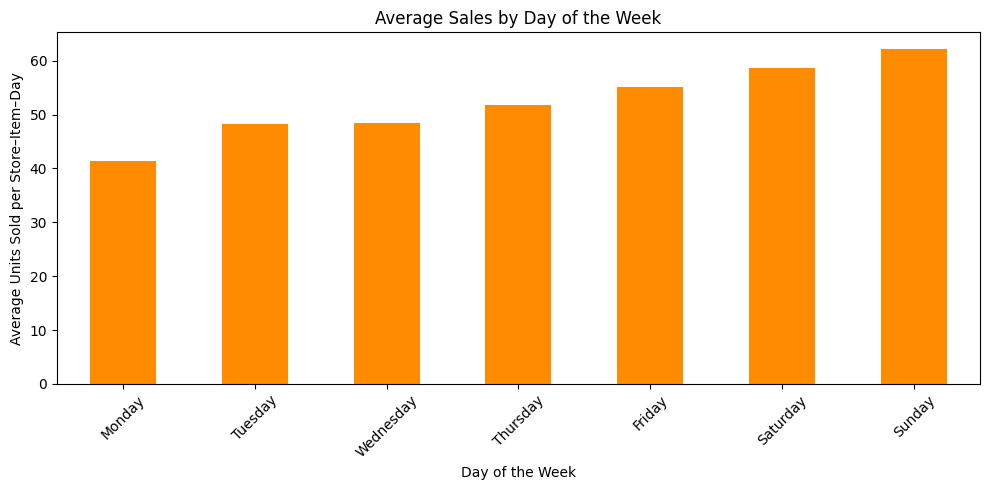

In [84]:
# Calculate average sales for each weekday
weekday_sales = train.groupby(
    train["date"].dt.dayofweek
)["sales"].mean()

# Replace weekday numbers with names
weekday_sales = weekday_sales.reindex(range(7))

weekday_sales.index = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

# Draw a bar chart
weekday_sales.plot(
    kind="bar",
    figsize=(10, 5),
    color="darkorange"
)

plt.title("Average Sales by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Units Sold per Store–Item–Day")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Conclusion: Average sales generally increase toward the weekend.
- Sunday has the highest average sales: approximately 62 units per store–item–day.
- Saturday is next, at approximately 59 units.
- Monday has the lowest average, at approximately 41 units.
This shows a weekly sales pattern, with higher sales on weekends.

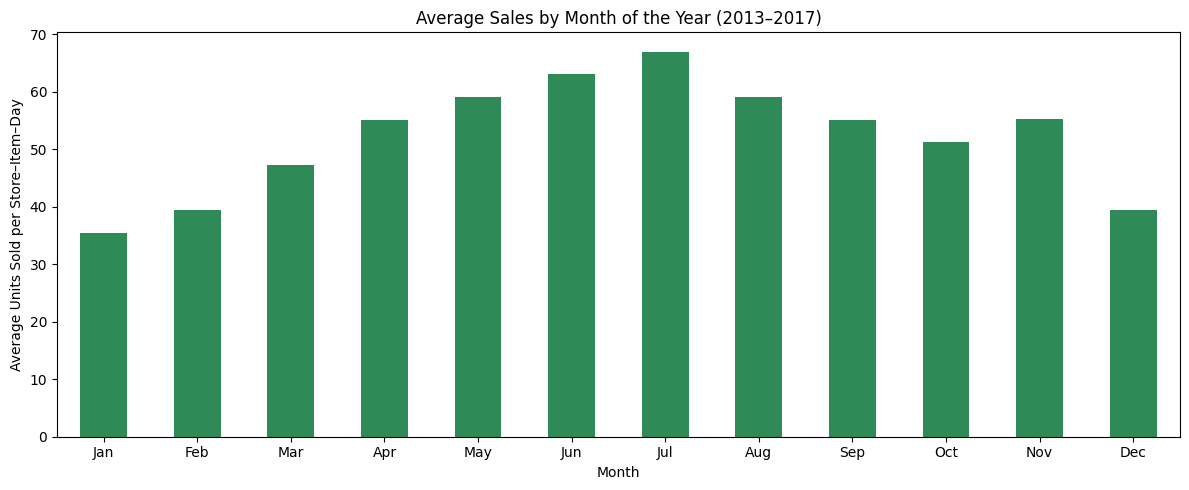

In [85]:
# Calculate average sales for each calendar month
month_sales = train.groupby(
    train["date"].dt.month
)["sales"].mean()

# Arrange months from January to December
month_sales = month_sales.reindex(range(1, 13))

# Replace month numbers with names
month_sales.index = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

# Draw a bar chart
month_sales.plot(
    kind="bar",
    figsize=(12, 5),
    color="seagreen"
)

plt.title("Average Sales by Month of the Year (2013–2017)")
plt.xlabel("Month")
plt.ylabel("Average Units Sold per Store–Item–Day")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Conclusion: Average sales rise from January to July, then generally decline toward December, with a small increase in November.
- July has the highest average: approximately 67 units per store–item–day.
- June is next, at approximately 63 units.
- January has the lowest average: approximately 35 units.
This supports a seasonal sales pattern, with higher sales around the middle of the year.

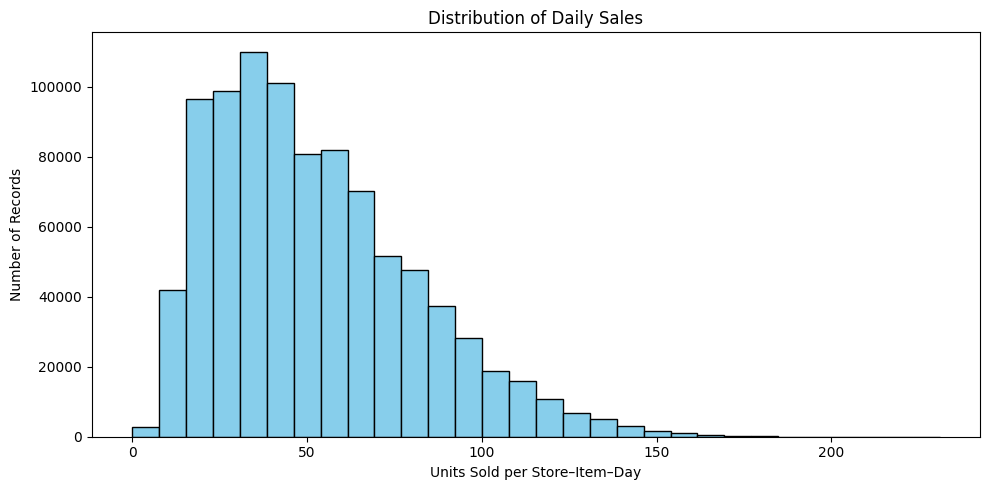

In [86]:
import matplotlib.pyplot as plt

# Draw a histogram of sales values
plt.figure(figsize=(10, 5))

plt.hist(
    train["sales"],
    bins=30,
    color="skyblue",
    edgecolor="black"
)

plt.title("Distribution of Daily Sales")
plt.xlabel("Units Sold per Store–Item–Day")
plt.ylabel("Number of Records")

plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

 histogram is right-skewed (positively skewed).
- Most sales values are concentrated on the left and middle.
- A few very high sales values form a long tail on the right.
Remember: the direction of the tail determines the skew. A longer right tail means right skew.

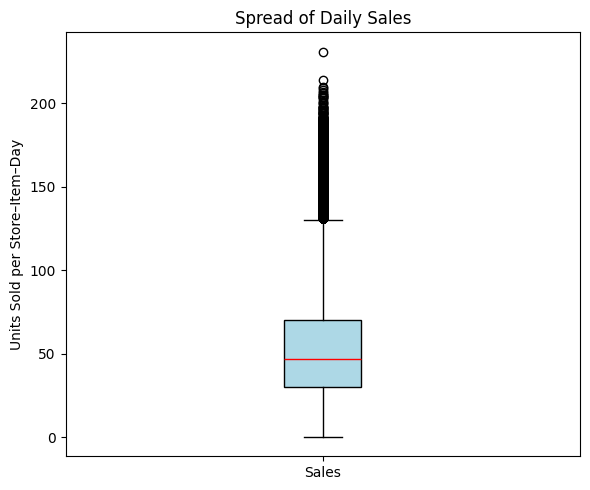

In [87]:
import matplotlib.pyplot as plt

# Draw a box plot of sales
plt.figure(figsize=(6, 5))

plt.boxplot(
    train["sales"],
    patch_artist=True,
    boxprops={"facecolor": "lightblue"},
    medianprops={"color": "red"}
)

plt.title("Spread of Daily Sales")
plt.ylabel("Units Sold per Store–Item–Day")
plt.xticks([1], ["Sales"])

plt.tight_layout()
plt.show()

The blue box shows that the middle half of the records have sales of about 30–70 units.
The red line shows the middle sales value: about 47 units.
The dots above show unusually high sales, above about 130 units.

In [88]:
# Find the lower and upper edges of the box
Q1 = train["sales"].quantile(0.25)
Q3 = train["sales"].quantile(0.75)

# Calculate the width of the middle 50% of values
IQR = Q3 - Q1

# Calculate the outlier limits
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Lower limit: -30.0
Upper limit: 130.0


In [89]:
potential_outliers = train[
    (train["sales"] < lower_limit) |
    (train["sales"] > upper_limit)
]

print("Number of flagged records:", len(potential_outliers))

potential_outliers.sort_values(
    "sales", ascending=False
).head(10)

Number of flagged records: 11967


,date,store,item,sales
118507,2017-07-02,2,15,231
130939,2016-07-17,2,22,214
114862,2017-07-09,2,13,210
118157,2016-07-17,2,15,209
123985,2017-07-02,2,18,208
118150,2016-07-10,2,15,207
142251,2017-07-08,2,28,206
173287,2017-07-02,2,45,205
173308,2017-07-23,2,45,205
118514,2017-07-09,2,15,205


In [90]:
# Select the same store and item around the highest-sales date
nearby_sales = train[
    (train["store"] == 2) &
    (train["item"] == 15) &
    (train["date"] >= "2017-06-18") &
    (train["date"] <= "2017-07-16")
].sort_values("date")

print(nearby_sales[["date", "sales"]])

             date  sales
118493 2017-06-18    190
118494 2017-06-19     99
118495 2017-06-20    156
118496 2017-06-21    150
118497 2017-06-22    142
118498 2017-06-23    157
118499 2017-06-24    155
118500 2017-06-25    198
118501 2017-06-26    110
118502 2017-06-27    150
118503 2017-06-28    147
118504 2017-06-29    151
118505 2017-06-30    169
118506 2017-07-01    186
118507 2017-07-02    231
118508 2017-07-03    136
118509 2017-07-04    145
118510 2017-07-05    162
118511 2017-07-06    159
118512 2017-07-07    162
118513 2017-07-08    175
118514 2017-07-09    205
118515 2017-07-10    134
118516 2017-07-11    149
118517 2017-07-12    150
118518 2017-07-13    152
118519 2017-07-14    172
118520 2017-07-15    169
118521 2017-07-16    194


“The highest sales record follows a pattern of high Sunday sales for the same store and item. It was retained because it may represent a genuine sales peak.”

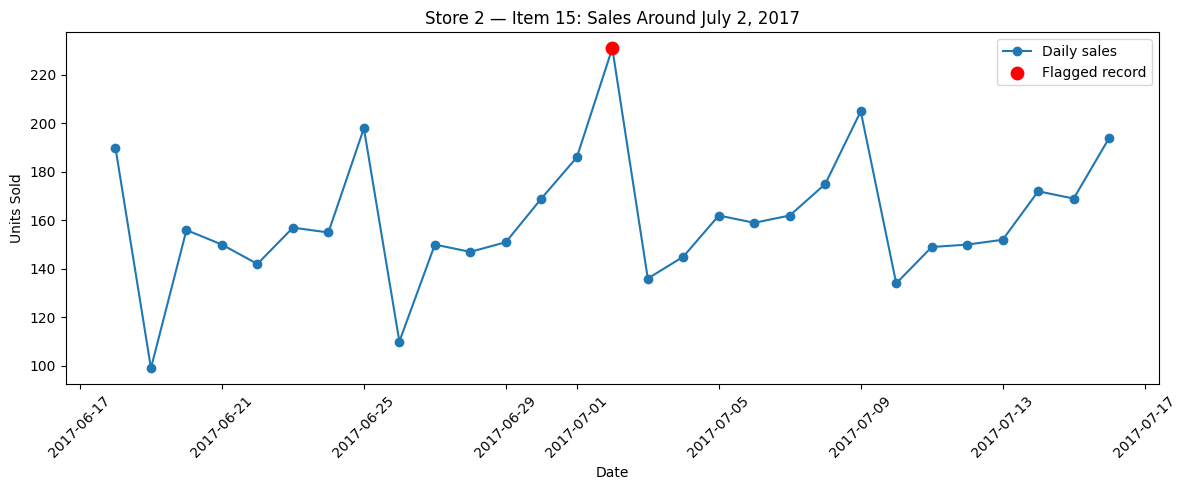

In [91]:
plt.figure(figsize=(12, 5))

plt.plot(
    nearby_sales["date"],
    nearby_sales["sales"],
    marker="o",
    label="Daily sales"
)

# Highlight the record we are investigating
plt.scatter(
    pd.Timestamp("2017-07-02"),
    231,
    color="red",
    s=80,
    label="Flagged record",
    zorder=3
)

plt.title("Store 2 — Item 15: Sales Around July 2, 2017")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

The red dot (231 units) is the highest peak, but it is not completely separate from the surrounding sales pattern.

In [92]:
print("Sales skewness:", train["sales"].skew())

Sales skewness: 0.8671122960235801


# Feature engineering

In [93]:
#Create three date features

# Extract the year
train["year"] = train["date"].dt.year

# Extract the month: January = 1, December = 12
train["month"] = train["date"].dt.month

# Extract the weekday: Monday = 0, Sunday = 6
train["day_of_week"] = train["date"].dt.dayofweek

Feature	====Purpose

year====	Helps represent differences between years

month===	Helps learn seasonal sales patterns

day_of_week	=====Helps learn weekly patterns, such as higher Sunday sales

In [94]:
train[
    ["date", "store", "item", "sales",
     "year", "month", "day_of_week"]
].head()

,date,store,item,sales,year,month,day_of_week
0,2013-01-01,1,1,13,2013,1,1
1,2013-01-02,1,1,11,2013,1,2
2,2013-01-03,1,1,14,2013,1,3
3,2013-01-04,1,1,13,2013,1,4
4,2013-01-05,1,1,10,2013,1,5


In [95]:
train.head()

,date,store,item,sales,year,month,day_of_week
0,2013-01-01,1,1,13,2013,1,1
1,2013-01-02,1,1,11,2013,1,2
2,2013-01-03,1,1,14,2013,1,3
3,2013-01-04,1,1,13,2013,1,4
4,2013-01-05,1,1,10,2013,1,5


In [96]:
train.tail()

,date,store,item,sales,year,month,day_of_week
912995,2017-12-27,10,50,63,2017,12,2
912996,2017-12-28,10,50,59,2017,12,3
912997,2017-12-29,10,50,74,2017,12,4
912998,2017-12-30,10,50,62,2017,12,5
912999,2017-12-31,10,50,82,2017,12,6


In [97]:
#Add day of the month and a weekend indicator
# Extract the day of the month: 1 to 31
train["day_of_month"] = train["date"].dt.day

# Mark Saturday and Sunday as weekends
train["is_weekend"] = (
    train["day_of_week"] >= 5
).astype(int)

In [98]:
train.head(7)

,date,store,item,sales,year,month,day_of_week,day_of_month,is_weekend
0,2013-01-01,1,1,13,2013,1,1,1,0
1,2013-01-02,1,1,11,2013,1,2,2,0
2,2013-01-03,1,1,14,2013,1,3,3,0
3,2013-01-04,1,1,13,2013,1,4,4,0
4,2013-01-05,1,1,10,2013,1,5,5,1
5,2013-01-06,1,1,12,2013,1,6,6,1
6,2013-01-07,1,1,10,2013,1,0,7,0


In [99]:
#Create a time index

In [100]:
# Store the first date as our reference
start_date = train["date"].min()

# Calculate days since that date
train["time_index"] = (
    train["date"] - start_date
).dt.days

In [101]:
train[["date", "store", "item", "time_index"]].head(7)

,date,store,item,time_index
0,2013-01-01,1,1,0
1,2013-01-02,1,1,1
2,2013-01-03,1,1,2
3,2013-01-04,1,1,3
4,2013-01-05,1,1,4
5,2013-01-06,1,1,5
6,2013-01-07,1,1,6


In [102]:
#Add past sales as a feature

train = train.sort_values(
    ["store", "item", "date"]
).reset_index(drop=True)

In [103]:
train["lag_364"] = train.groupby(
    ["store", "item"]
)["sales"].shift(364)

In [104]:
#Inspect where the lag first becomes available
train.loc[
    (train["store"] == 1) & (train["item"] == 1),
    ["date", "store", "item", "sales", "lag_364"]
].iloc[360:368]

,date,store,item,sales,lag_364
360,2013-12-27,1,1,18,NaN
361,2013-12-28,1,1,17,NaN
362,2013-12-29,1,1,14,NaN
363,2013-12-30,1,1,5,NaN
364,2013-12-31,1,1,15,13.0
365,2014-01-01,1,1,9,11.0
366,2014-01-02,1,1,14,14.0
367,2014-01-03,1,1,11,13.0


This feature gives the model past sales information to help predict future sales. NaN means unavailable history, not zero sales

In [105]:
#Average past sales over 28 days
train["past_year_mean_28"] = train.groupby(
    ["store", "item"]
)["sales"].transform(
    lambda s: s.shift(364).rolling(
        window=28,
        min_periods=28
    ).mean()
)

In [106]:
train.loc[
    (train["store"] == 1) & (train["item"] == 1),
    ["date", "sales", "lag_364", "past_year_mean_28"]
].iloc[388:396]

,date,sales,lag_364,past_year_mean_28
388,2014-01-24,18,14.0,NaN
389,2014-01-25,21,12.0,NaN
390,2014-01-26,16,12.0,NaN
391,2014-01-27,8,11.0,10.714286
392,2014-01-28,6,6.0,10.464286
393,2014-01-29,13,9.0,10.392857
394,2014-01-30,11,13.0,10.357143
395,2014-01-31,18,11.0,10.285714


This feature shows the average sales level over a past 28-day period. It gives the model a smoother picture than using just one past day’s sales.

In [107]:
#Check missing values

print(
    train[["lag_364", "past_year_mean_28"]].isna().sum()
)

lag_364              182000
past_year_mean_28    195500
dtype: int64


In [108]:

#Create the dataset for model training
model_data = train.dropna(
    subset=["lag_364", "past_year_mean_28"]
).copy()

In [109]:
print("Original rows:", len(train))
print("Rows available for modelling:", len(model_data))

print(
    "Rows excluded from modelling:",
    len(train) - len(model_data)
)

print(
    model_data[["lag_364", "past_year_mean_28"]]
    .isna()
    .sum()
)

Original rows: 913000
Rows available for modelling: 717500
Rows excluded from modelling: 195500
lag_364              0
past_year_mean_28    0
dtype: int64


Feature	How we create it in test data

year, month, day_of_week, day_of_month	= Extract from the test date

is_weekend	= Check whether the test date is Saturday or Sunday

time_index	= Count days from the same start date used for training

lag_364  = 	Look up sales from 364 days earlier for the same store and item, using training history

past_year_mean_28	= Calculate the same 28-day average using the required historical sales

# Time-Based Train–Validation–Holdout Split

We’ll divide model_data into three parts:

Part	= Purpose
 
Training	= The model learns from these records

Validation	= We compare models and choose their settings

Holdout = 	We evaluate the selected model on later, unseen records

In [110]:
# Older records for training
train_data = model_data[
    model_data["date"] < "2017-07-05"
].copy()

# Next 90 days for validation
validation_data = model_data[
    (model_data["date"] >= "2017-07-05") &
    (model_data["date"] < "2017-10-03")
].copy()

# Final 90 days for holdout evaluation
holdout_data = model_data[
    model_data["date"] >= "2017-10-03"
].copy()

Training: The model learns from past sales.

Validation: We compare predictions with actual sales to choose a model.

Holdout: We check the chosen model on another unseen period.

Test data: We predict future sales, whose actual values are unknown.

In [111]:
print("Training rows:", len(train_data))
print("Validation rows:", len(validation_data))
print("Holdout rows:", len(holdout_data))

Training rows: 627500
Validation rows: 45000
Holdout rows: 45000


In [112]:
print(
    "Training:",
    train_data["date"].min(),
    "to",
    train_data["date"].max()
)

print(
    "Validation:",
    validation_data["date"].min(),
    "to",
    validation_data["date"].max()
)

print(
    "Holdout:",
    holdout_data["date"].min(),
    "to",
    holdout_data["date"].max()
)

Training: 2014-01-27 00:00:00 to 2017-07-04 00:00:00
Validation: 2017-07-05 00:00:00 to 2017-10-02 00:00:00
Holdout: 2017-10-03 00:00:00 to 2017-12-31 00:00:00


#After splitting the data, we select the input features (X) and the target (y).
X = information the model uses to make predictions.
y = actual sales we want the model to learn to predict.

In [113]:
#input feature
features = [
    "store",
    "item",
    "year",
    "month",
    "day_of_week",
    "day_of_month",
    "is_weekend",
    "time_index",
    "lag_364",
    "past_year_mean_28"
]

In [114]:
model_data.head()

,date,store,item,sales,year,month,day_of_week,day_of_month,is_weekend,time_index,lag_364,past_year_mean_28
391,2014-01-27,1,1,8,2014,1,0,27,0,391,11.0,10.714286
392,2014-01-28,1,1,6,2014,1,1,28,0,392,6.0,10.464286
393,2014-01-29,1,1,13,2014,1,2,29,0,393,9.0,10.392857
394,2014-01-30,1,1,11,2014,1,3,30,0,394,13.0,10.357143
395,2014-01-31,1,1,18,2014,1,4,31,0,395,11.0,10.285714


In [115]:
# Training data
X_train = train_data[features].copy()
y_train = train_data["sales"].copy()

# Validation data
X_val = validation_data[features].copy()
y_val = validation_data["sales"].copy()

# Holdout data
X_holdout = holdout_data[features].copy()
y_holdout = holdout_data["sales"].copy()

In [116]:
print("Training inputs:", X_train.shape)
print("Training target:", y_train.shape)

print("Validation inputs:", X_val.shape)
print("Holdout inputs:", X_holdout.shape)

Training inputs: (627500, 10)
Training target: (627500,)
Validation inputs: (45000, 10)
Holdout inputs: (45000, 10)


In [117]:
#Make baseline predictions
# Use sales from 364 days earlier as the prediction
baseline_predictions = X_val["lag_364"].copy()

In [118]:
#Compare predictions with actual sales
baseline_comparison = validation_data[
    ["date", "store", "item"]
].copy()

baseline_comparison["actual_sales"] = y_val
baseline_comparison["predicted_sales"] = baseline_predictions

display(baseline_comparison.head(10))

,date,store,item,actual_sales,predicted_sales
1646,2017-07-05,1,1,23,22.0
1647,2017-07-06,1,1,31,33.0
1648,2017-07-07,1,1,32,34.0
1649,2017-07-08,1,1,27,35.0
1650,2017-07-09,1,1,32,28.0
1651,2017-07-10,1,1,16,18.0
1652,2017-07-11,1,1,23,27.0
1653,2017-07-12,1,1,29,30.0
1654,2017-07-13,1,1,22,22.0
1655,2017-07-14,1,1,38,33.0


In [119]:
#Calculate the average prediction error
from sklearn.metrics import mean_absolute_error

baseline_mae = mean_absolute_error(
    y_val,
    baseline_predictions
)

print("Baseline MAE:", round(baseline_mae, 2))

Baseline MAE: 9.2


The baseline predicted sales using the same store and item’s sales from 364 days earlier. It achieved an MAE of 9.2, meaning predictions differed from actual sales by 9.2 units on average. We will use this result to check whether our machine learning model makes better predictions.

# TRAIN ML MODEL

In [120]:
from sklearn.ensemble import HistGradientBoostingRegressor

In [121]:
model = HistGradientBoostingRegressor(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=31,
    categorical_features=[0, 1],
    early_stopping=False,
    random_state=42
)

In [122]:
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


Predict validation sales and check the error

In [123]:
validation_predictions = model.predict(X_val)

model_mae = mean_absolute_error(
    y_val,
    validation_predictions
)

print("Baseline MAE:", round(baseline_mae, 2))
print("Model MAE:", round(model_mae, 2))

Baseline MAE: 9.2
Model MAE: 6.78


The machine learning model predicts sales more accurately than copying sales from 364 days earlier on our validation data. We still need to check its performance on the holdout data.

: Try improving the model

In [124]:
#Create and train another model

In [125]:
tuned_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.1,
    max_leaf_nodes=31,
    categorical_features=[0, 1],
    early_stopping=False,
    random_state=42
)

tuned_model.fit(X_train, y_train)

print("Tuned model training completed!")

Tuned model training completed!


In [126]:
tuned_predictions = tuned_model.predict(X_val)

tuned_mae = mean_absolute_error(
    y_val,
    tuned_predictions
)

print("Baseline MAE:", round(baseline_mae, 2))
print("Original model MAE:", round(model_mae, 2))
print("Tuned model MAE:", round(tuned_mae, 2))

Baseline MAE: 9.2
Original model MAE: 6.78
Tuned model MAE: 6.68


In [ ]:
tuned_predictions = tuned_model.predict(X_val)

tuned_mae = mean_absolute_error(
    y_val,
    tuned_predictions
)

print("Baseline MAE:", round(baseline_mae, 2))
print("Original model MAE:", round(model_mae, 2))
print("Tuned model MAE:", round(tuned_mae, 2))

Baseline MAE: 9.2
Original model MAE: 6.78
Tuned model MAE: 6.68


In [127]:
if tuned_mae < model_mae:
    best_model = tuned_model
    print("Selected: 200-round model")
else:
    best_model = model
    print("Selected: 100-round model")

Selected: 200-round model


Increasing the learning rounds reduced the average error slightly, from 6.78 to 6.68 units.

We select the 200-round model because it has the lowest validation MAE. Its error is about 27.4% lower than the baseline

Predict holdout sales

In [128]:
# Select the model that had the lower validation error
best_model = tuned_model

# Predict sales for the holdout period
holdout_predictions = best_model.predict(X_holdout)

In [129]:
holdout_mae = mean_absolute_error(
    y_holdout,
    holdout_predictions
)

print("Holdout Model MAE:", round(holdout_mae, 2))

Holdout Model MAE: 6.11


In [130]:
holdout_baseline_predictions = X_holdout["lag_364"].copy()

holdout_baseline_mae = mean_absolute_error(
    y_holdout,
    holdout_baseline_predictions
)

print("Holdout Baseline MAE:", round(holdout_baseline_mae, 2))
print("Holdout Model MAE:", round(holdout_mae, 2))

Holdout Baseline MAE: 8.35
Holdout Model MAE: 6.11


The model reduced the average error by 2.24 units, approximately 26.8%.

Conclusion: The model predicts sales more accurately than copying sales from 364 days earlier, even on data not used for training or model selection.

In [135]:
test.head()

,id,date,store,item
0,0,2018-01-01,1,1
1,1,2018-01-02,1,1
2,2,2018-01-03,1,1
3,3,2018-01-04,1,1
4,4,2018-01-05,1,1


In [138]:
test.tail()

,id,date,store,item
44995,44995,2018-03-27,10,50
44996,44996,2018-03-28,10,50
44997,44997,2018-03-29,10,50
44998,44998,2018-03-30,10,50
44999,44999,2018-03-31,10,50


# : Prepare the test data’s date features

In [131]:
test_features = test.copy()

test_features["date"] = pd.to_datetime(test_features["date"])

In [132]:
test_features["year"] = test_features["date"].dt.year

test_features["month"] = test_features["date"].dt.month

test_features["day_of_week"] = test_features["date"].dt.dayofweek

test_features["day_of_month"] = test_features["date"].dt.day

test_features["is_weekend"] = (
    test_features["day_of_week"] >= 5
).astype(int)

In [133]:
# Use the same starting date used for training
start_date = train["date"].min()

test_features["time_index"] = (
    test_features["date"] - start_date
).dt.days

In [134]:
display(
    test_features[
        [
            "date",
            "store",
            "item",
            "year",
            "month",
            "day_of_week",
            "day_of_month",
            "is_weekend",
            "time_index"
        ]
    ].head()
)

print("Test rows:", len(test_features))

,date,store,item,year,month,day_of_week,day_of_month,is_weekend,time_index
0,2018-01-01,1,1,2018,1,0,1,0,1826
1,2018-01-02,1,1,2018,1,1,2,0,1827
2,2018-01-03,1,1,2018,1,2,3,0,1828
3,2018-01-04,1,1,2018,1,3,4,0,1829
4,2018-01-05,1,1,2018,1,4,5,0,1830


Test rows: 45000


Prepare the historical sales

In [143]:
history = train[
    ["date", "store", "item", "sales"]
].copy()

history = history.sort_values(
    ["store", "item", "date"]
)

# Calculate the 28-day average separately for each store and item
history["past_year_mean_28"] = (
    history.groupby(["store", "item"])["sales"]
    .transform(
        lambda s: s.rolling(window=28, min_periods=28).mean()
    )
)

Move the matching dates forward by 364 days

In [144]:
history["date"] = history["date"] + pd.Timedelta(days=364)

history = history.rename(
    columns={"sales": "lag_364"}
)

Attach the historical features to the test rows

In [145]:
# Remove previous copies if this cell is run again
test_features = test_features.drop(
    columns=["lag_364", "past_year_mean_28"],
    errors="ignore"
)

test_features = test_features.merge(
    history,
    on=["date", "store", "item"],
    how="left",
    validate="one_to_one"
)

Check the results

In [146]:
display(
    test_features[
        ["date", "store", "item", "lag_364", "past_year_mean_28"]
    ].head()
)

print("Test rows:", len(test_features))

print(
    test_features[
        ["lag_364", "past_year_mean_28"]
    ].isna().sum()
)

,date,store,item,lag_364,past_year_mean_28
0,2018-01-01,1,1,15,16.071429
1,2018-01-02,1,1,10,16.071429
2,2018-01-03,1,1,16,16.035714
3,2018-01-04,1,1,14,16.000000
4,2018-01-05,1,1,24,16.607143


Test rows: 45000
lag_364              0
past_year_mean_28    0
dtype: int64


# Train the final model and predict future sales

Prepare the inputs

In [147]:
# All historical records with complete features
X_full = model_data[features].copy()
y_full = model_data["sales"].copy()

# Test inputs in the same column order
X_test = test_features[features].copy()

print("Final training inputs:", X_full.shape)
print("Test inputs:", X_test.shape)

Final training inputs: (717500, 10)
Test inputs: (45000, 10)


In [148]:
from sklearn.base import clone

# Copy the selected settings into a fresh, untrained model
final_model = clone(best_model)

# Learn from all eligible historical records
final_model.fit(X_full, y_full)

print("Final model training completed!")

Final model training completed!


In [149]:
test_predictions = final_model.predict(X_test)

Create the forecast table

In [150]:
forecast = test_features[
    ["id", "date", "store", "item"]
].copy()

forecast["predicted_sales"] = test_predictions

display(forecast.head(10))

print("Number of predictions:", len(forecast))

,id,date,store,item,predicted_sales
0,0,2018-01-01,1,1,12.796279
1,1,2018-01-02,1,1,14.549279
2,2,2018-01-03,1,1,14.878615
3,3,2018-01-04,1,1,15.865110
4,4,2018-01-05,1,1,17.440499
5,5,2018-01-06,1,1,17.992500
6,6,2018-01-07,1,1,19.732810
7,7,2018-01-08,1,1,13.464805
8,8,2018-01-09,1,1,14.995457
9,9,2018-01-10,1,1,15.133449


Number of predictions: 45000


In Step 13, we prepared the test features, retrained the selected model using all eligible historical data, and predicted sales for 45,000 store–item–day records from January to March 2018. These forecasts can help stores plan stock. Their accuracy cannot be measured yet because the test data has no actual sales values.

Create an output folder

In [151]:
from pathlib import Path

output_folder = Path("outputs")
output_folder.mkdir(exist_ok=True)

Save the model and its feature information

In [152]:
import joblib

model_bundle = {
    "model": final_model,
    "features": features,
    "start_date": start_date
}

joblib.dump(
    model_bundle,
    output_folder / "sales_forecasting_model.joblib"
)

print("Model saved!")

Model saved!


Save the future forecasts

In [153]:
forecast.to_csv(
    output_folder / "sales_forecasts.csv",
    index=False
)

print("Forecasts saved:", len(forecast))

Forecasts saved: 45000


Save historical sales and holdout results for the dashboard

In [154]:
train[["date", "store", "item", "sales"]].to_csv(
    output_folder / "historical_sales.csv",
    index=False
)

# Preserve predictions from the earlier holdout evaluation
holdout_results = holdout_data[
    ["date", "store", "item"]
].copy()

holdout_results["actual_sales"] = y_holdout
holdout_results["predicted_sales"] = holdout_predictions
holdout_results["baseline_sales"] = holdout_baseline_predictions

holdout_results.to_csv(
    output_folder / "holdout_results.csv",
    index=False
)

print("Historical sales and holdout results saved!")

Historical sales and holdout results saved!


In [155]:
print("Saved folder:", output_folder.resolve())

for file in sorted(output_folder.iterdir()):
    print(file.name)

Saved folder: C:\Users\Alana Nabhan\Desktop\SALES FORCASTING\outputs
historical_sales.csv
holdout_results.csv
sales_forecasting_model.joblib
sales_forecasts.csv


In [156]:
%pip install streamlit

  Using cached jsonschema-4.26.0-py3-none-any.whl.metadata (7.6 kB)
  Using cached jsonschema_specifications-2025.9.1-py3-none-any.whl.metadata (2.9 kB)
   ---------------------------------------- 0.0/10.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.4 MB 660.6 kB/s eta 0:00:16
   ---------------------------------------- 0.1/10.4 MB 1.1 MB/s eta 0:00:10
    --------------------------------------- 0.2/10.4 MB 1.5 MB/s eta 0:00:07
    --------------------------------------- 0.2/10.4 MB 1.4 MB/s eta 0:00:08
   - -------------------------------------- 0.3/10.4 MB 1.4 MB/s eta 0:00:08
   - -------------------------------------- 0.3/10.4 MB 1.2 MB/s eta 0:00:09
   - -------------------------------------- 0.3/10.4 MB 1.1 MB/s eta 0:00:10
   - -------------------------------------- 0.4/10.4 MB 1.2 MB/s eta 0:00:09
   - -------------------------------------- 0.4/10.4 MB 1.1 MB/s eta 0:00:09
   - -------------------------------------- 0.4/10.4 MB 1.1 MB/s eta 0:00:09
   - 

ERROR: Could not install packages due to an OSError: [WinError 2] The system cannot find the file specified: 'c:\\python312\\Scripts\\jsonschema.exe' -> 'c:\\python312\\Scripts\\jsonschema.exe.deleteme'


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Create a file named app.py